## Problem 19 (14/100 points): Explainability

This problem focuses on explainability using Captum.

Following examples we have discussed in class, do the following:
* Load the standard MNIST training and test sets.
* Build and train a PyTorch classifier that achieves greater than 90% accuracy on the test set. If you tune the model, use a validation split from the training set; reserve the test set for final evaluation. Print the final test accuracy.
* Choose 10 distinct samples at random from the test set, using a sampling seed of 42. Put your model in evaluation mode and use Captum's integrated gradients to attribute each image's predicted-class score to its input pixels. Use the predicted class as the attribution target, even if the prediction is incorrect.
* Use an all-black image as the attribution baseline. Apply the same preprocessing to the baseline as to the input images; if you normalize inputs, the baseline must represent black after that normalization. State your preprocessing and baseline choice.
* Display each of the 10 images alongside its attribution heatmap, with the true and predicted labels. Explain the heatmap's color scale and whether it shows signed contributions or their magnitudes. Briefly interpret each map, describing which regions contribute most to the predicted-class score relative to the baseline.
* Export your trained model in evaluation mode to an ONNX file using `torch.onnx.export`.

Notes:
* Run `uv sync` from the repository root to install the required dependencies, including Captum, ONNX, and ONNX Script. Use the project's `.venv` notebook kernel.
* Submit the notebook with its accuracy output, attribution plots, explanations, and export code. You do not need to commit the model file or downloaded MNIST data.
* MNIST is a solved problem. If you choose the right model and tune it well, it should fit quickly.
* If you get stuck, remember best practices for model tuning.

This is an open-ended coding problem testing PyTorch for model construction and training, Captum for attribution, and ONNX for model export. You may use other tools in addition to these required tools.

This problem will be graded manually.

/Users/zionharris/midterm-mine/.venv-intel/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [00:00<00:00, 17436930.87it/s]


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 539863.69it/s]


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:00<00:00, 9249677.54it/s]


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 953193.67it/s]

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw



Finished epoch 1/3
Finished epoch 2/3
Finished epoch 3/3
Test accuracy: 0.9658


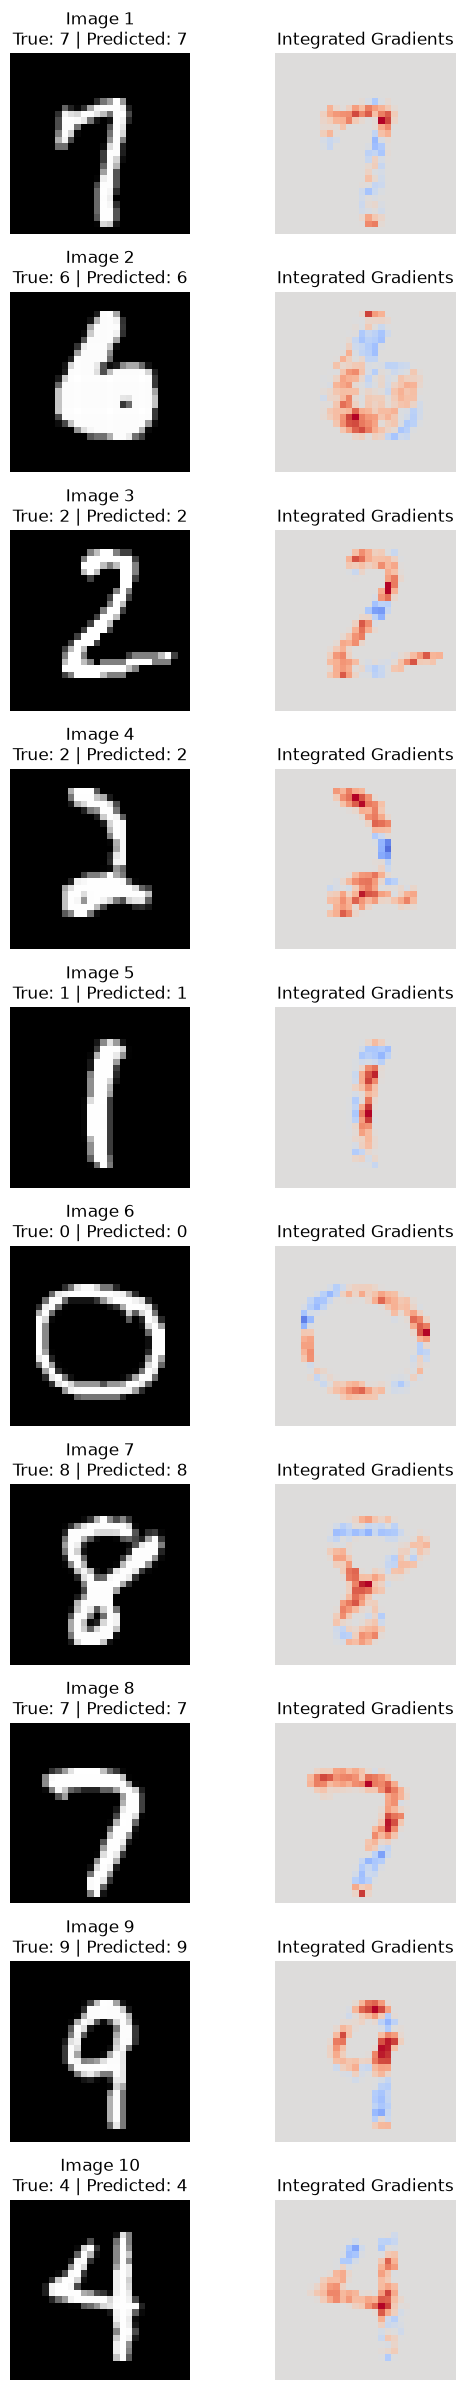

Exported model to mnist_classifier.onnx


In [2]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from captum.attr import IntegratedGradients

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cpu")

# MNIST data; ToTensor means an all-zero image is a valid black baseline
transform = transforms.ToTensor()

train_set = datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
test_set = datasets.MNIST(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = DataLoader(test_set, batch_size=256, shuffle=False)

# Simple fully connected classifier
class MNISTClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.network(x)


model = MNISTClassifier().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Train
for epoch in range(3):
    model.train()

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_function(outputs, labels)
        loss.backward()
        optimizer.step()

    print(f"Finished epoch {epoch + 1}/3")

# Evaluate
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images.to(device))
        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels.to(device)).sum().item()
        total += labels.size(0)

test_accuracy = correct / total
print(f"Test accuracy: {test_accuracy:.4f}")

# Select 10 distinct test images using seed 42
rng = np.random.default_rng(42)
selected_indices = rng.choice(len(test_set), size=10, replace=False)

selected_images = torch.stack([test_set[i][0] for i in selected_indices])
true_labels = torch.tensor([test_set[i][1] for i in selected_indices])

# Predictions
with torch.no_grad():
    outputs = model(selected_images)
    predicted_labels = outputs.argmax(dim=1)

# Integrated Gradients
ig = IntegratedGradients(model)
baseline = torch.zeros_like(selected_images)
attributions = []

for i in range(10):
    attribution = ig.attribute(
        selected_images[i:i + 1],
        baselines=baseline[i:i + 1],
        target=int(predicted_labels[i]),
        n_steps=50,
    )
    attributions.append(attribution.squeeze().detach().numpy())

# Display images and attribution heatmaps
fig, axes = plt.subplots(10, 2, figsize=(6, 24))

for i in range(10):
    image = selected_images[i].squeeze().numpy()
    attribution = attributions[i]

    axes[i, 0].imshow(image, cmap="gray")
    axes[i, 0].set_title(
        f"Image {i + 1}\nTrue: {true_labels[i].item()} | "
        f"Predicted: {predicted_labels[i].item()}"
    )
    axes[i, 0].axis("off")

    limit = np.max(np.abs(attribution))
    axes[i, 1].imshow(
        attribution,
        cmap="coolwarm",
        vmin=-limit,
        vmax=limit,
    )
    axes[i, 1].set_title("Integrated Gradients")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

# Export the model to ONNX
model.eval()
dummy_input = torch.zeros(1, 1, 28, 28)

torch.onnx.export(
    model,
    dummy_input,
    "mnist_classifier.onnx",
    input_names=["images"],
    output_names=["logits"],
    opset_version=17,
)

print("Exported model to mnist_classifier.onnx")

### Integrated Gradients Explanation

The black image was used as the baseline. The heatmaps show signed contributions to the model’s predicted class: red pixels support the prediction, while blue pixels work against it. Gray areas have little effect.

For each example, the strongest red regions usually follow the important strokes of the digit. Blue regions show pixels that do not match the predicted digit or areas where the image differs from the black baseline. The heatmaps show which parts of each image influenced the model’s prediction the most.